In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots/paper', exist_ok=True)

In [2]:
# PGD transfer at the eps where the white box is ~100% successful (postprocess.pgd_attack_exp:
# white-box eps sweep, then fp32 models + fp64 cross-entropy, alpha 2/255, 75 steps, random start)
df = pd.read_csv('data/pgd_attack_exp.csv')
main = df[df.source != 'white_box_sweep']
res_high_eps = {
    'eps_255': int(main.eps_255.iloc[0]),
    'num_traces': [int(k) for k in main[main.source == 'HD'].traces_k],
    'HD': list(main[main.source == 'HD'].asr),
    'HW': list(main[main.source == 'HW'].asr),
    'surrogate': main[main.source == 'surrogate'].asr.item(),
    'white_box': main[main.source == 'white_box'].asr.item(),
}

eps = 5/255, white box 0.9982, surrogate 0.8013


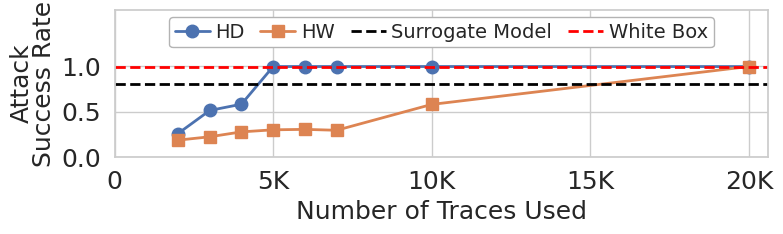

(<Figure size 800x250 with 1 Axes>,
 <Axes: xlabel='Number of Traces Used', ylabel='Attack\nSuccess Rate'>)

In [3]:
# Wide and short, 18 pt, no x rotation, legend inside on a white background.
# Writes ../plots/paper/adv_transfer_squashed.pdf.
def plot_asr_squashed(res, save_name='adv_transfer_squashed', figsize=(8, 2.5), font_size=18):
    sns.set(style="whitegrid")
    x = np.asarray(res['num_traces'], dtype=float)
    fig, ax = plt.subplots(figsize=figsize)
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    for i, (lm, mk) in enumerate([('HD', 'o'), ('HW', 's')]):
        ax.plot(x, res[lm], '-', marker=mk, linewidth=2.0, markersize=9, label=lm, color=colors[i])
    ax.axhline(res['surrogate'], linestyle='--', color='black', linewidth=2, label='Surrogate Model')
    ax.axhline(res['white_box'], linestyle='--', color='red', linewidth=2, label='White Box')
    ax.set_ylim(0, 1.62)                      # headroom so the legend row clears the white-box line
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xlim(0, 20.6)
    ax.set_xticks([0, 5, 10, 15, 20])
    ax.set_xticklabels(['0', '5K', '10K', '15K', '20K'])
    ax.set_xlabel('Number of Traces Used', fontsize=font_size)
    ax.set_ylabel('Attack\nSuccess Rate', fontsize=font_size, linespacing=0.9)
    ax.tick_params(axis='both', labelsize=font_size)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=4, fontsize=font_size - 4, frameon=True,
              facecolor='white', edgecolor='0.7', framealpha=1.0, borderpad=0.3,
              handletextpad=0.3, columnspacing=0.8, labelspacing=0.2, handlelength=1.8)
    plt.tight_layout()
    fig.savefig(f"../plots/paper/{save_name}.pdf", format="pdf", bbox_inches="tight",
                metadata={"Creator": "Matplotlib"})
    plt.show()
    return fig, ax

print(f"eps = {res_high_eps['eps_255']}/255, white box {res_high_eps['white_box']:.4f}, "
      f"surrogate {res_high_eps['surrogate']:.4f}")
plot_asr_squashed(res_high_eps)